# Módulo 2: Extracción de Características y Descriptores
## Trabajo Práctico 4: Descriptores Profundos (Deep Features)

**Cátedra:** Visión por Computadora — 5to Año
**FICH-UNL (Santa Fe, Argentina)**

### Objetivos del Trabajo Práctico:
1. Comprender la transición histórica desde las características diseñadas a mano (*hand-crafted*) hacia las representaciones aprendidas jerárquicas.
2. Implementar y entrenar una Red Neuronal Convolucional (CNN) básica para clasificación supervisada, evaluando el desempeño nativo de su capa de salida directamente sobre datos de test.
3. Configurar la integración de un dataset personalizado obtenido de Kaggle o HuggingFace para la clasificación de prendas de ropa.
4. Implementar un Autoencoder bajo una arquitectura en "reloj de arena" (*hourglass*) para compresión no supervisada.
5. Extraer descriptores del espacio latente y clasificarlos mediante vecinos cercanos ($k$-NN con $k=3$) para analizar su separabilidad geométrica.

---

### Celda de Configuración Inicial (Obligatoria)
Ejecutá esta celda para cargar las dependencias esenciales de PyTorch, herramientas de visualización, Scikit-Learn y para definir las funciones auxiliares de graficación.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, Dataset, random_split
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2 as cv
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier


In [2]:
# Fijar semillas para reproducibilidad
torch.manual_seed(42)
np.random.seed(42)

# Función auxiliar para mostrar reconstrucciones del Autoencoder
def mostrar_reconstruccion(original, reconstruida, titulo="Reconstrucción"):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(original, cmap='gray')
    ax[0].set_title("Original (256x256)")
    ax[0].axis('off')

    ax[1].imshow(reconstruida, cmap='gray')
    ax[1].set_title(titulo)
    ax[1].axis('off')
    plt.tight_layout()
    plt.show()

print("✅ Entorno inicial de Deep Features configurado con éxito.")

✅ Entorno inicial de Deep Features configurado con éxito.


---
## Sección de Preparación y Carga de Datasets

En esta sección configuraremos el dataset de imágenes de prendas de vestir. Tienen dos pasos:
1. **Paso 1:** Utilizar el generador de texturas sintéticas (Lana, Denim, Polka Dots) que autogenera imágenes de $256\times256$ para asegurar que el notebook sea ejecutable inmediatamente.
2. **Paso 2:** Cargar un dataset real desde Kaggle o HuggingFace. Sigan las instrucciones comentadas para montar Drive, descargar el zip con el token de la API de Kaggle, descomprimir las carpetas y cargarlas usando la clase personalizada `DatasetPrendas`.

In [5]:
import kagglehub

path = kagglehub.dataset_download(
    "paramaggarwal/fashion-product-images-small"
)

print(path)

100%|██████████| 565M/565M [01:56<00:00, 5.09MB/s] 

Extracting files...


C:\Users\MATEOCRACK\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1


In [8]:
import os

print(os.listdir(path))

print(os.listdir(os.path.join(path, "myntradataset")))

['images', 'myntradataset']
['images', 'styles.csv']


In [ ]:
import pandas as pd
import os

ruta_csv = os.path.join(path, "myntradataset", "styles.csv")

df = pd.read_csv(
    ruta_csv,
    on_bad_lines="warn"
)



      id gender masterCategory subCategory  articleType baseColour  season  \
0  15970    Men        Apparel     Topwear       Shirts  Navy Blue    Fall   
1  39386    Men        Apparel  Bottomwear        Jeans       Blue  Summer   
2  59263  Women    Accessories     Watches      Watches     Silver  Winter   
3  21379    Men        Apparel  Bottomwear  Track Pants      Black    Fall   
4  53759    Men        Apparel     Topwear      Tshirts       Grey  Summer   

     year   usage                             productDisplayName  
0  2011.0  Casual               Turtle Check Men Navy Blue Shirt  
1  2012.0  Casual             Peter England Men Party Blue Jeans  
2  2016.0  Casual                       Titan Women Silver Watch  
3  2011.0  Casual  Manchester United Men Solid Black Track Pants  
4  2012.0  Casual                          Puma Men Grey T-shirt  
(44424, 10)


C:\Users\MATEOCRACK\AppData\Local\Temp\ipykernel_24684\3096684054.py:6: ParserWarning: Skipping line 6044: expected 10 fields, saw 11
Skipping line 6569: expected 10 fields, saw 11
Skipping line 7399: expected 10 fields, saw 11
Skipping line 7939: expected 10 fields, saw 11
Skipping line 9026: expected 10 fields, saw 11
Skipping line 10264: expected 10 fields, saw 11
Skipping line 10427: expected 10 fields, saw 11
Skipping line 10905: expected 10 fields, saw 11
Skipping line 11373: expected 10 fields, saw 11
Skipping line 11945: expected 10 fields, saw 11
Skipping line 14112: expected 10 fields, saw 11
Skipping line 14532: expected 10 fields, saw 11
Skipping line 15076: expected 10 fields, saw 12
Skipping line 29906: expected 10 fields, saw 11
Skipping line 31625: expected 10 fields, saw 11
Skipping line 33020: expected 10 fields, saw 11
Skipping line 35748: expected 10 fields, saw 11
Skipping line 35962: expected 10 fields, saw 11
Skipping line 37770: expected 10 fields, saw 11
Skippi

In [13]:
print(df.head())


      id gender masterCategory subCategory  articleType baseColour  season  \
0  15970    Men        Apparel     Topwear       Shirts  Navy Blue    Fall   
1  39386    Men        Apparel  Bottomwear        Jeans       Blue  Summer   
2  59263  Women    Accessories     Watches      Watches     Silver  Winter   
3  21379    Men        Apparel  Bottomwear  Track Pants      Black    Fall   
4  53759    Men        Apparel     Topwear      Tshirts       Grey  Summer   

     year   usage                             productDisplayName  
0  2011.0  Casual               Turtle Check Men Navy Blue Shirt  
1  2012.0  Casual             Peter England Men Party Blue Jeans  
2  2016.0  Casual                       Titan Women Silver Watch  
3  2011.0  Casual  Manchester United Men Solid Black Track Pants  
4  2012.0  Casual                          Puma Men Grey T-shirt  


In [14]:

class DatasetPrendas(Dataset):
    """
    Clase personalizada para cargar y procesar imágenes
    de prendas de vestir.

    Estandariza el tamaño a 256x256 y convierte
    las imágenes a escala de grises.
    """

    def __init__(self, imagenes, etiquetas, transform=None):

        self.imagenes = imagenes
        self.etiquetas = etiquetas
        self.transform = transform

    def __len__(self):

        return len(self.imagenes)

    def __getitem__(self, idx):

        img = self.imagenes[idx]
        label = self.etiquetas[idx]

        # Redimensionar a 256x256
        img = cv.resize(img, (256, 256))

        # Convertir a escala de grises
        img = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

        # Normalizar al rango [0, 1]
        img = img.astype("float32") / 255.0

        # Convertir a tensor
        # (256, 256) -> (1, 256, 256)
        img_tensor = torch.tensor(
            img,
            dtype=torch.float32
        ).unsqueeze(0)

        # Etiqueta como tensor entero
        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return img_tensor, label



In [15]:
import os
import cv2 as cv
import torch

from torch.utils.data import Dataset, DataLoader, random_split



# ------------------------------------------------------------
# 1. Seleccionar las 5 clases con más imágenes
# ------------------------------------------------------------

clases = df["articleType"].value_counts().head(5).index.tolist()

print("Clases seleccionadas:")
print(clases)


# ------------------------------------------------------------
# 2. Filtrar el DataFrame
# ------------------------------------------------------------

df_filtrado = df[df["articleType"].isin(clases)].copy()

print("\nCantidad de registros por clase:")
print(df_filtrado["articleType"].value_counts())


# ------------------------------------------------------------
# 3. Crear etiquetas numéricas
# ------------------------------------------------------------

mapa_clases = {
    clase: i
    for i, clase in enumerate(clases)
}

df_filtrado["label"] = df_filtrado["articleType"].map(mapa_clases)

print("\nMapa de clases:")
print(mapa_clases)


# ------------------------------------------------------------
# 4. Ubicación de las imágenes
# ------------------------------------------------------------

ruta_images = os.path.join(path, "myntradataset", "images")

print("\nCarpeta de imágenes:")
print(ruta_images)


# ------------------------------------------------------------
# 5. Cargar imágenes y etiquetas
# ------------------------------------------------------------

imagenes = []
etiquetas = []

for _, fila in df_filtrado.iterrows():

    nombre_imagen = f"{int(fila['id'])}.jpg"
    ruta_imagen = os.path.join(ruta_images, nombre_imagen)

    img = cv.imread(ruta_imagen)

    # Comprobar que la imagen exista
    if img is not None:
        imagenes.append(img)
        etiquetas.append(fila["label"])


print("\nDatos cargados:")
print("Imágenes:", len(imagenes))
print("Etiquetas:", len(etiquetas))





Clases seleccionadas:
['Tshirts', 'Shirts', 'Casual Shoes', 'Watches', 'Sports Shoes']

Cantidad de registros por clase:
articleType
Tshirts         7067
Shirts          3217
Casual Shoes    2845
Watches         2542
Sports Shoes    2036
Name: count, dtype: int64

Mapa de clases:
{'Tshirts': 0, 'Shirts': 1, 'Casual Shoes': 2, 'Watches': 3, 'Sports Shoes': 4}

Carpeta de imágenes:
C:\Users\MATEOCRACK\.cache\kagglehub\datasets\paramaggarwal\fashion-product-images-small\versions\1\myntradataset\images

Datos cargados:
Imágenes: 17704
Etiquetas: 17704


In [ ]:
dataset_completo = DatasetPrendas(
    imagenes=imagenes,
    etiquetas=etiquetas
)

clases_dataset = clases


len_train = int(0.8 * len(dataset_completo))
len_test = len(dataset_completo) - len_train

dataset_train, dataset_test = random_split(
    dataset_completo,
    [len_train, len_test]
)



train_loader = DataLoader(
    dataset_train,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    dataset_test,
    batch_size=16,
    shuffle=False
)



print("\n======================================")
print("Inicialización de datos completada")
print("======================================")

print(f"Total de muestras: {len(dataset_completo)}")
print(f"Train: {len_train}")
print(f"Test: {len_test}")

print("\nCategorías:")
for i, clase in enumerate(clases_dataset):
    print(f"{i} -> {clase}")


Inicialización de datos completada
Total de muestras: 17704
Train: 14163
Test: 3541

Categorías:
0 -> Tshirts
1 -> Shirts
2 -> Casual Shoes
3 -> Watches
4 -> Sports Shoes


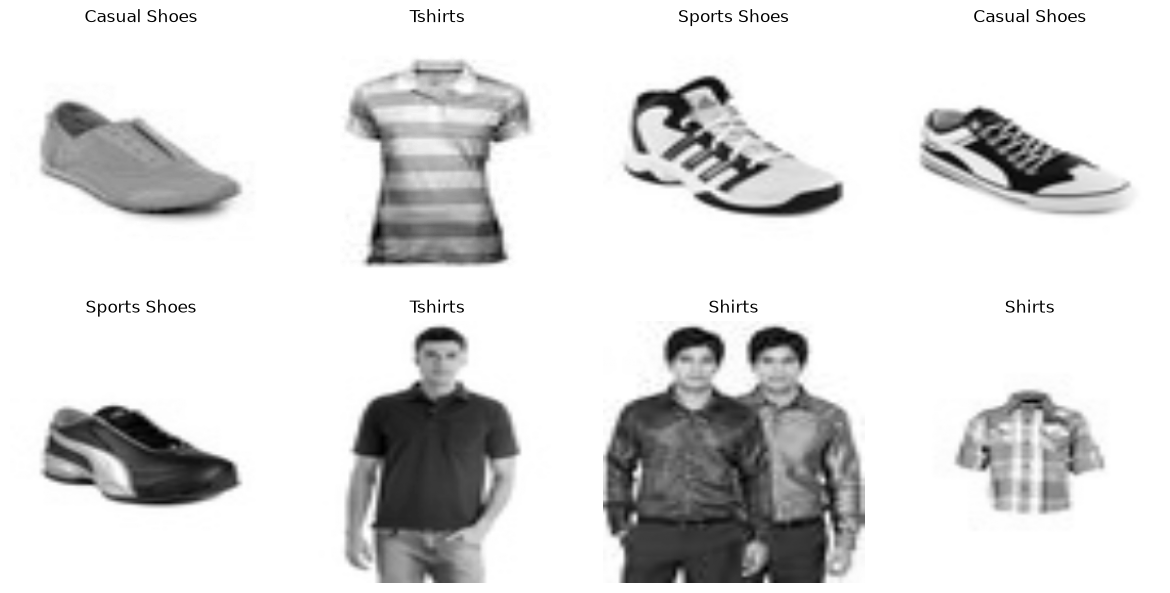

In [17]:
import matplotlib.pyplot as plt

# Obtener un batch del train_loader
X_batch, y_batch = next(iter(train_loader))

# Mostrar 8 imágenes
plt.figure(figsize=(12, 6))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    # Sacamos el canal: (1, 256, 256) -> (256, 256)
    img = X_batch[i].squeeze(0)

    plt.imshow(img, cmap="gray")

    # Convertimos la etiqueta numérica al nombre de la clase
    clase = clases_dataset[y_batch[i].item()]

    plt.title(clase)
    plt.axis("off")

plt.tight_layout()
plt.show()

---
## Ejercicio 1: Extracción de Características y Clasificación Supervisada con CNN

### Objetivo:
Diseñar y entrenar una red CNN estándar de 5 capas en un entorno supervisado. Posteriormente, evaluar el clasificador nativo final directamente sobre el conjunto de test para medir el rendimiento de generalización.

In [18]:
class ClasificadorCNN_5Capas(nn.Module):
    def __init__(self, num_clases=3):
        super(ClasificadorCNN_5Capas, self).__init__()

        # 3 Capas convolucionales de extracción espacial
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1)  # Capa de pesos 1
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1) # Capa de pesos 2
        self.conv3 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1) # Capa de pesos 3

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.relu = nn.ReLU()

        # 2 Capas lineales de clasificación completando las 5 capas de la red
        # El tamaño espacial de 256x256 se reduce a 32x32 tras pasar por 3 MaxPools consecutivos (256->128->64->32)
        self.fc1 = nn.Linear(32 * 32 * 32, 128) # Capa de pesos 4 (Penúltima capa: Vector embedding de 128D)
        self.fc2 = nn.Linear(128, num_clases)     # Capa de pesos 5 (Clasificador nativo final de salida)

    def forward(self, x):
        # Primera capa convolucional
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Segunda capa convolucional
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        # Tercera capa convolucional
        x = self.conv3(x)
        x = self.relu(x)
        x = self.pool(x)

        # Aplanar para pasar de mapas de características a vector
        x = x.view(x.size(0), -1)

        # Capas completamente conectadas
        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)

        return x

In [19]:
# Inicializar instancias de optimización
num_clases_actual = len(clases_dataset)
modelo_cnn = ClasificadorCNN_5Capas(num_clases=num_clases_actual)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelo_cnn.parameters(),lr=0.001)


# BUCLE DE ENTRENAMIENTO SUPERVISADO
epochs = 5
modelo_cnn.train()
for epoch in range(epochs):
    loss_acumulada = 0.0
    for imagenes, etiquetas in train_loader:
        optimizer.zero_grad()
        salidas = modelo_cnn(imagenes)
        loss = criterion(salidas, etiquetas)
        loss.backward()
        optimizer.step()
        loss_acumulada += loss.item()

    print(f"Época [{epoch+1}/{epochs}] - "f"Loss promedio: {loss_acumulada/len(train_loader):.4f}")

Época [1/5] - Loss promedio: 0.4537
Época [2/5] - Loss promedio: 0.2686
Época [3/5] - Loss promedio: 0.1927
Época [4/5] - Loss promedio: 0.1457
Época [5/5] - Loss promedio: 0.1144


### Evaluación Directa de la CNN entrenada sobre el Conjunto de Test
Para evaluar correctamente el rendimiento de generalización del clasificador de la CNN supervisada, **debemos alimentar al modelo entrenado única y exclusivamente con los datos de prueba (`test_loader`)**. Mediremos su desempeño clasificatorio nativo analizando las predicciones de su última capa (`fc2`), sin extraer descriptores ni realizar KNNs de entrenamiento intermedios.

⏳ Evaluando generalización directa de la CNN sobre el conjunto de prueba...

📊 Reporte de Clasificación Nativa Convolucional sobre Test:
              precision    recall  f1-score   support

     Tshirts       0.97      0.95      0.96      1417
      Shirts       0.89      0.95      0.92       661
Casual Shoes       0.85      0.91      0.88       569
     Watches       0.99      0.99      0.99       498
Sports Shoes       0.86      0.77      0.81       396

    accuracy                           0.93      3541
   macro avg       0.91      0.91      0.91      3541
weighted avg       0.93      0.93      0.93      3541



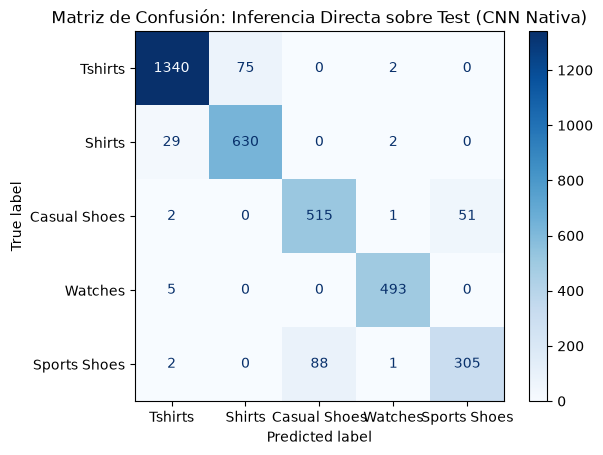

In [20]:
def evaluar_cnn_directo_test(modelo, data_loader):
    """
    Evalúa el desempeño de clasificación sobre el conjunto de prueba utilizando
    la salida del clasificador nativo de la CNN (logits en fc2).
    """
    modelo.eval()  # Desactivar modo entrenamiento (hooks, dropout, etc.)

    y_true = []
    y_pred = []

    with torch.no_grad():  # Desactivar cálculo de gradientes en inferencia
        for imagenes, etiquetas in data_loader:
            outputs = modelo(imagenes)

            _, predicciones = torch.max(outputs, dim=1) #tomo solo el maximo

            y_true.extend(etiquetas.numpy())
            y_pred.extend(predicciones.cpu().numpy())

    return np.array(y_true), np.array(y_pred)


try:
    print("⏳ Evaluando generalización directa de la CNN sobre el conjunto de prueba...")

    y_true_cnn, y_pred_cnn = evaluar_cnn_directo_test(modelo_cnn,test_loader)

    print("\n📊 Reporte de Clasificación Nativa Convolucional sobre Test:")
    print(classification_report(y_true_cnn,y_pred_cnn,target_names=clases_dataset))

    # Graficar Matriz de Confusión
    cm = confusion_matrix(
        y_true_cnn,
        y_pred_cnn
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=clases_dataset
    )

    disp.plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(
        "Matriz de Confusión: "
        "Inferencia Directa sobre Test (CNN Nativa)"
    )

    plt.show()


except Exception as e:

    print(
        "❌ Error en la ejecución: "
        "Verificá tu arquitectura y completá los bloques # TODO de test."
    )

    print("Detalle:", e)

💡 **Reflexión Guía - Ejercicio 1:**
1. Explicá de forma precisa el concepto de **jerarquía semántica** en el aprendizaje profundo. ¿Qué diferencias operacionales existen entre los filtros espaciales que se aprenden en la primera capa (`conv1`) y los descriptores abstractos vectorizados de la penúltima capa lineal (`fc1`)?
2. En este ejercicio evaluamos la CNN usando la inferencia directa del test set. ¿Por qué sería un desvío conceptual grave extraer embeddings de entrenamiento (`train_loader`) y procesar una clasificación por KNN para validar esta red convolucional, cuando ésta ya posee su propia capa de pesos lineales supervisada (`fc2`) entrenada específicamente para clasificar?
3. Si tuvieran que exportar esta red para operar en tiempo real en un dispositivo embebido con procesador de bajo consumo, ¿cómo influye el diseño lineal plano de `fc1` ($32 \times 32 \times 32$ neuronas de entrada) en la memoria y cuál sería una alternativa de compresión espacial arquitectónica?

**Enlaces y Lecturas Sugeridas:**
- [PyTorch Conv2d API Reference](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)
- [Visualizing Feature Maps in CNNs](https://pytorch.org/tutorials/beginner/saving_loading_models.html)

---
## Ejercicio 2: Autoencoder de 5 Capas y Clasificación Latente mediante $k$-NN ($k=3$)

### Objetivo:
Construir y entrenar de forma no supervisada un Autoencoder convolucional con arquitectura de reloj de arena (*hourglass*). Luego, extraer las coordenadas comprimidas del espacio latente para alimentar un clasificador clásico KNN con $k=3$ y comprobar la separabilidad del agrupamiento no supervisado.

In [ ]:
class Autoencoder_5Capas(nn.Module):
    def __init__(self):
        super(Autoencoder_5Capas, self).__init__()

        # ENCODER (5 Capas de compresión lineal y convolucional progresiva)
        # Reducción espacial progresiva: 256 -> 128 -> 64 -> 32 -> 16
        self.enc_conv1 = nn.Conv2d(1, 8, kernel_size=3, stride=2, padding=1)   # Capa de pesos 1
        self.enc_conv2 = nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1)  # Capa de pesos 2
        self.enc_conv3 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1) # Capa de pesos 3
        self.enc_conv4 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1) # Capa de pesos 4
        self.enc_fc = nn.Linear(64 * 16 * 16, 32)                             # Capa de pesos 5 (Capa Bottleneck: Espacio Latente de 32D)

        # DECODER (5 Capas de reconstrucción convolucional simétrica traspuesta)
        self.dec_fc = nn.Linear(32, 64 * 16 * 16)                             # Capa de pesos 1 del decoder
        self.dec_conv1 = nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1) # Capa de pesos 2 (16 -> 32)
        self.dec_conv2 = nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1) # Capa de pesos 3 (32 -> 64)
        self.dec_conv3 = nn.ConvTranspose2d(16, 8, kernel_size=3, stride=2, padding=1, output_padding=1)  # Capa de pesos 4 (64 -> 128)
        self.dec_conv4 = nn.ConvTranspose2d(8, 1, kernel_size=3, stride=2, padding=1, output_padding=1)   # Capa de pesos 5 (128 -> 256)

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def encode(self, x):
        x = self.relu(self.enc_conv1(x))
        x = self.relu(self.enc_conv2(x))
        x = self.relu(self.enc_conv3(x))
        x = self.relu(self.enc_conv4(x))
        x = x.view(x.size(0), -1)
        z = self.enc_fc(x)  # Vector latente comprimido Z (32 dimensiones)
        return z

    def decode(self, z):
        x = self.relu(self.dec_fc(z))
        x = x.view(x.size(0), 64, 16, 16)

        # Decodificación convolucional simétrica
        x = self.relu(self.dec_conv1(x))
        x = self.relu(self.dec_conv2(x))
        x = self.relu(self.dec_conv3(x))

        # Última capa: reconstrucción en rango [0, 1]
        x_reconstruida = self.sigmoid(self.dec_conv4(x))

        return x_reconstruida

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)



In [22]:
autoencoder = Autoencoder_5Capas()

criterion_ae = nn.MSELoss()

optimizer_ae = optim.Adam(
    autoencoder.parameters(),
    lr=0.001
)

epochs_ae = 5
autoencoder.train()

for epoch in range(epochs_ae):
    loss_acum = 0.0
    for imagenes, _ in train_loader:
        optimizer_ae.zero_grad()
        imagenes_reconstruidas = autoencoder(imagenes)
        loss = criterion_ae(
            imagenes_reconstruidas,
            imagenes
        )
        loss.backward()
        optimizer_ae.step()
        loss_acum += loss.item()

    print(
        f"Época [{epoch+1}/{epochs_ae}] - "
        f"Loss MSE: {loss_acum/len(train_loader):.6f}"
    )

Época [1/5] - Loss MSE: 0.027677
Época [2/5] - Loss MSE: 0.007995
Época [3/5] - Loss MSE: 0.006559
Época [4/5] - Loss MSE: 0.005931
Época [5/5] - Loss MSE: 0.005536


### Extracción del Espacio Latente y Clasificación mediante $k$-NN ($k=3$)
Como el Autoencoder aprende bajo un paradigma estrictamente no supervisado (solo optimiza reconstrucción de píxeles), carece de un clasificador lineal final nativo.
Para validar si la compresión agrupó de forma compacta y separable las texturas, **extraeremos las variables latentes de 32D para los subconjuntos de train y de test**, y ajustaremos un clasificador clásico $3$-NN de Scikit-Learn.

⏳ Extrayendo representaciones del espacio latente comprimido (32D)...

📊 Reporte de Clasificación sobre Espacio Latente (Autoencoder + 3-NN):
              precision    recall  f1-score   support

     Tshirts       0.92      0.90      0.91      1417
      Shirts       0.80      0.84      0.82       661
Casual Shoes       0.82      0.86      0.84       569
     Watches       0.99      0.99      0.99       498
Sports Shoes       0.78      0.71      0.74       396

    accuracy                           0.87      3541
   macro avg       0.86      0.86      0.86      3541
weighted avg       0.87      0.87      0.87      3541



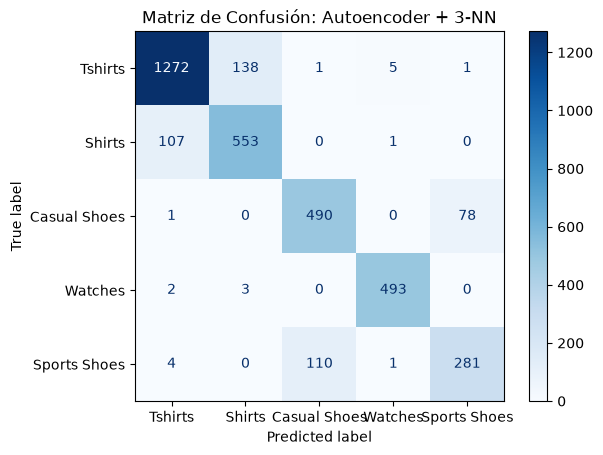

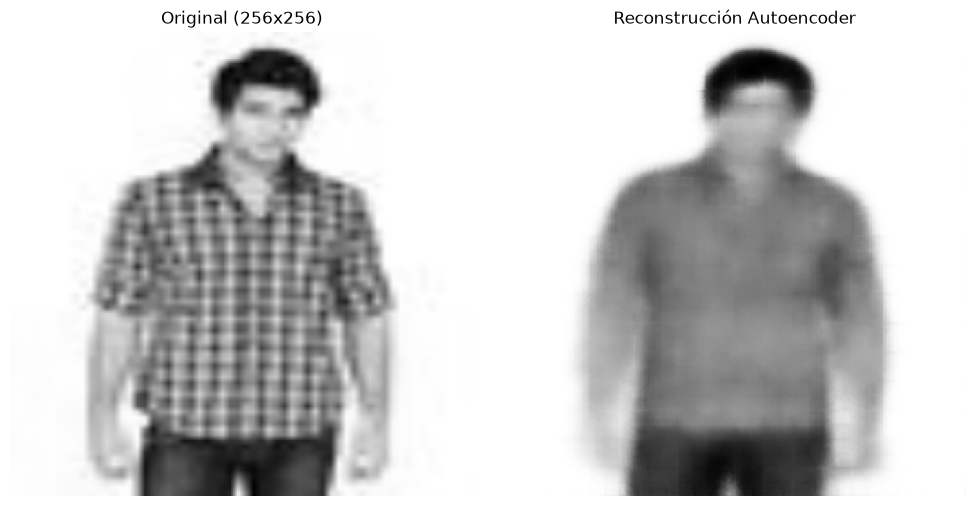

In [23]:
from sklearn.neighbors import KNeighborsClassifier


def extraer_espacio_latente(modelo, data_loader):
    modelo.eval()

    z_acumulado = []
    y_acumulado = []

    with torch.no_grad():

        for imagenes, etiquetas in data_loader:
            z = modelo.encode(imagenes)
            z_acumulado.append(z.cpu().numpy())
            y_acumulado.append(etiquetas.numpy())

    return (np.concatenate(z_acumulado, axis=0),np.concatenate(y_acumulado, axis=0))
try:
    print("⏳ Extrayendo representaciones del espacio latente comprimido (32D)...")

    X_train_latente, y_train_latente = extraer_espacio_latente(autoencoder,train_loader)
    X_test_latente, y_test_latente = extraer_espacio_latente(autoencoder,test_loader)

    knn_ae = KNeighborsClassifier(n_neighbors=3)

    # Entrenar k-NN utilizando el espacio latente
    knn_ae.fit(X_train_latente,y_train_latente) #calculamos centroides
    y_pred_ae = knn_ae.predict(X_test_latente) #predecimos el test

    print("\n📊 Reporte de Clasificación sobre Espacio Latente (Autoencoder + 3-NN):")
    print(classification_report(y_test_latente,y_pred_ae,target_names=clases_dataset))

    cm = confusion_matrix(y_test_latente,y_pred_ae)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=clases_dataset)

    disp.plot(cmap="Blues",values_format="d")
    plt.title("Matriz de Confusión: ""Autoencoder + 3-NN")
    plt.show()

    muestra_img = dataset_completo[0][0].unsqueeze(0)
    reconstruida_img = (autoencoder(muestra_img).detach().squeeze().numpy())

    mostrar_reconstruccion(muestra_img.squeeze().numpy(),reconstruida_img,"Reconstrucción Autoencoder")


except Exception as e:

    print(
        "❌ Error en la ejecución: "
        "Completá el entrenamiento del Autoencoder "
        "y el clasificador k-NN."
    )

    print("Detalle:", e)

💡 **Reflexión Guía - Ejercicio 2:**
1. Explique matemáticamente el principio del **cuello de botella** (*bottleneck*). ¿Por qué al forzar la red a pasar toda la información estructural de una imagen de $256\times256$ por una capa reducida de solo 32 variables lineales se logra aislar las redundancias espaciales y descartar el ruido de alta frecuencia?
2. El Autoencoder se optimiza de forma no supervisada minimizando el error de reconstrucción de píxeles L2 sin conocer las etiquetas de las prendas. ¿Por qué aun así este espacio latente resulta altamente representativo para que un clasificador lineal/no-lineal simple como KNN logre agrupar y discriminar exitosamente las texturas?
3. ¿Qué ocurre con la topología del espacio latente y la estabilidad de reconstrucción si reducimos la dimensionalidad del cuello de botella a un extremo físico (por ejemplo, $z = f(x) \in \mathbb{R}^2$)?

**Enlaces y Lecturas Sugeridas:**
- [Comprehensive Guide to Autoencoders in PyTorch](https://pytorch.org/tutorials/beginner/intro_to_pytorch_learning.html)
- [Scikit-Learn KNeighborsClassifier API](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)

---
## Ejercicio 3: Detección de Anomalías y Muestras Fuera de Distribución (Out-of-Distribution - OOD)

### Introducción Teórica
Las redes neuronales convolucionales entrenadas bajo el paradigma de clasificación supervisada sufren de **"sobreconfianza catastrófica"**. Debido a que la última capa densa (FC2/Softmax) divide el espacio de características mediante hiperplanos geométricos continuos, cualquier imagen que se introduzca al modelo —incluso ruido estocástico o patrones abstractos que la red jamás vio— será clasificada en una de las clases conocidas con un nivel de confianza absurdamente alto.

> **La red "no sabe que no sabe".**



Para solucionar esta limitación de seguridad, implementaremos un detector **Out-of-Distribution (OOD)** basado en la topología métrica de los descriptores profundos (embeddings).

### Metodología del Ejercicio:
1. **Extracción y Centroides:** Utilizaremos la CNN entrenada de 5 capas como un extractor de características puro para procesar todo el conjunto de entrenamiento (`train_loader`). Extraeremos el vector descriptor de 128 dimensiones de la penúltima capa (`fc1`) para cada muestra y calcularemos el **centroide geométrico** (vector promedio $\vec{\mu}_c$) para cada una de las $C$ clases conocidas.

2. **Umbrales de Aceptación Métricos:** Para cada clase, calcularemos la distancia Euclídea clásica ($L_2$) de todos sus vectores de entrenamiento hacia su respectivo centroide. Definiremos el umbral de aceptación física $\theta_c$ utilizando el **Percentil 95** de dicho histograma de distancias, tolerando un 5% de variabilidad natural interna de los datos de entrenamiento.

3. **Muestra Intrusora (Anomalía):** Generaremos un conjunto de test anómalo compuesto por patrones geométricos de **Rayas de Cebra** (líneas de altísimo contraste vertical/horizontal). Esta estructura es geométricamente muy diferente a la Lana, el Denim o los Polka Dots, pero la red intentará clasificarla.

4. **Regla de Decisión con Filtro de Rechazo:** Al evaluar una nueva imagen de test:
   * Calcularemos su distancia Euclídea hacia cada uno de los centroides conocidos.
   * Si la distancia al centroide de la clase asignada por el clasificador supera el umbral límite establecido ($\min d_c > \theta_c$), el sistema **rechazará la muestra** catalogándola como **"Out-of-Distribution (OOD)"**, en lugar de dar un diagnóstico falso.

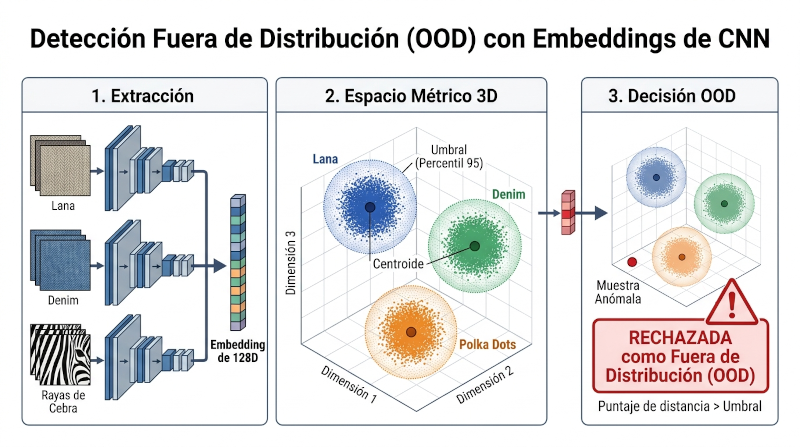

In [25]:
# Código de Programación
import torch
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, TensorDataset


# ==========================================
# FUNCIÓN AUXILIAR: EXTRAER EMBEDDING FC1
# ==========================================

def obtener_embedding_cnn(modelo, x):
    """
    Propaga las imágenes por la CNN hasta la salida de FC1.

    Devuelve un embedding de 128 dimensiones por imagen.
    """

    # Capas convolucionales
    x = modelo.conv1(x)
    x = modelo.relu(x)
    x = modelo.pool(x)

    x = modelo.conv2(x)
    x = modelo.relu(x)
    x = modelo.pool(x)

    x = modelo.conv3(x)
    x = modelo.relu(x)
    x = modelo.pool(x)

    # Aplanar
    x = x.view(x.size(0), -1)

    # Penúltima capa: embedding 128D
    x = modelo.fc1(x)
    x = modelo.relu(x)

    return x


# ==========================================
# GESTIÓN Y GENERACIÓN DE LA ANOMALÍA OOD
# ==========================================

def generar_patron_cebra_ood(n_muestras=40):
    """
    Genera un conjunto de imágenes anómalas (Rayas de Cebra)
    que la red jamás vio en train.
    """

    X_ood = []
    y_ood = []

    grid = np.linspace(0, 50, 256)
    u, v = np.meshgrid(grid, grid)

    for i in range(n_muestras):

        # Generar rayas verticales u horizontales
        if i % 2 == 0:
            img = (np.sin(u * 4) > 0.0).astype(float)
        else:
            img = (np.cos(v * 4) > 0.0).astype(float)

        # Añadir ruido leve
        ruido = np.random.normal(
            0,
            0.05,
            (256, 256)
        )

        img = np.clip(
            img + ruido,
            0.0,
            1.0
        )

        X_ood.append(img)
        y_ood.append(-1)

    X_ood = np.expand_dims(
        np.array(X_ood),
        axis=1
    )

    return (
        torch.tensor(X_ood, dtype=torch.float32),
        torch.tensor(y_ood, dtype=torch.long)
    )



In [26]:

# Generamos las muestras de anomalías
X_anomalo, y_anomalo = generar_patron_cebra_ood(30)
loader_ood_test = DataLoader(TensorDataset(X_anomalo, y_anomalo),batch_size=16,shuffle=False
)


# ==========================================
# ALGORITMO: CENTROIDES Y UMBRALES
# ==========================================

def caracterizar_espacio_entrenamiento(modelo,loader_train,device="cpu"):

    modelo.eval()

    # Crear una lista para cada clase
    embeddings_por_clase = {clase: []for clase in range(len(clases_dataset))}

    with torch.no_grad():
        for imagenes, etiquetas in loader_train:
            imagenes = imagenes.to(device)

            embeddings = obtener_embedding_cnn(modelo,imagenes)

            emb_np = embeddings.cpu().numpy()
            et_np = etiquetas.numpy()

            for emb, etiqueta in zip(emb_np,et_np):

                if etiqueta in embeddings_por_clase:
                    embeddings_por_clase[etiqueta].append(emb)


    centroides = {}
    umbrales_aceptacion = {}


    # --------------------------------------
    # 2. Calcular centroide y umbral
    # --------------------------------------

    for clase, lista_embs in embeddings_por_clase.items():

        embs_arr = np.array(lista_embs)

        # Centroide geométrico:
        # promedio de todos los embeddings de la clase
        centroides[clase] = np.mean(
            embs_arr,
            axis=0
        )

        # Distancia de cada muestra al centroide
        distancias = np.linalg.norm(
            embs_arr - centroides[clase],
            axis=1
        )

        # Umbral = percentil 95
        umbrales_aceptacion[clase] = np.percentile(
            distancias,
            95
        )

        print(
            f"Clase {clase} ({clases_dataset[clase]}): "
            f"Centroide calculado. "
            f"Umbral límite (Percentil 95): "
            f"{umbrales_aceptacion[clase]:.4f}"
        )

    return centroides, umbrales_aceptacion


# ==========================================
# INFERENCIA CON DETECTOR OOD ACTIVO
# ==========================================

def clasificar_con_detector_ood(
    modelo,
    centroides,
    umbrales,
    loader_datos,
    es_anomalo_esperado=False,
    device="cpu"
):

    modelo.eval()

    muestras_procesadas = 0
    muestras_rechazadas = 0
    predicciones_normales = []

    print(
        f"\nEvaluando "
        f"{'OOD Anomalous' if es_anomalo_esperado else 'Standard Test'} Loader:"
    )

    with torch.no_grad():

        for imagenes, etiquetas in loader_datos:

            imagenes = imagenes.to(device)

            # --------------------------------------
            # A. Predicción nativa de la CNN
            # --------------------------------------

            outputs = modelo(imagenes)

            _, preds_nativas = torch.max(
                outputs,
                dim=1
            )

            # --------------------------------------
            # B. Obtener embedding 128D
            # --------------------------------------

            embeddings = obtener_embedding_cnn(
                modelo,
                imagenes
            )

            emb_np = embeddings.cpu().numpy()

            preds_np = preds_nativas.cpu().numpy()


            # --------------------------------------
            # C. Analizar cada muestra
            # --------------------------------------

            for i in range(len(imagenes)):

                muestras_procesadas += 1

                clase_asignada = preds_np[i]

                vector_emb = emb_np[i]


                # Centroide de la clase predicha
                centroide_clase = centroides[
                    clase_asignada
                ]

                # Umbral de esa clase
                umbral_clase = umbrales[
                    clase_asignada
                ]


                # ----------------------------------
                # Distancia Euclídea
                # ----------------------------------

                distancia_al_centroide = np.linalg.norm(
                    vector_emb - centroide_clase
                )


                # ----------------------------------
                # Regla de decisión OOD
                # ----------------------------------

                es_anomalia = (
                    distancia_al_centroide > umbral_clase
                )


                # ----------------------------------
                # Resultado
                # ----------------------------------

                if es_anomalia:

                    muestras_rechazadas += 1

                    if muestras_procesadas <= 5:

                        print(
                            f" -> Muestra {muestras_procesadas}: "
                            f"🚨 RECHAZADA. "
                            f"Distancia "
                            f"{distancia_al_centroide:.4f} > "
                            f"Umbral "
                            f"{umbral_clase:.4f}. "
                            f"(Clasificador sugería Clase "
                            f"{clase_asignada})"
                        )

                else:

                    predicciones_normales.append(
                        clase_asignada
                    )

                    if (
                        muestras_procesadas <= 5
                        and not es_anomalo_esperado
                    ):

                        print(
                            f" -> Muestra {muestras_procesadas}: "
                            f"✅ ACEPTADA. "
                            f"Clasificada como Clase "
                            f"{clase_asignada} "
                            f"(Distancia "
                            f"{distancia_al_centroide:.4f} <= "
                            f"Umbral "
                            f"{umbral_clase:.4f})"
                        )


    # --------------------------------------
    # Tasa de rechazo
    # --------------------------------------

    tasa_rechazo = (
        muestras_rechazadas
        / muestras_procesadas
    ) * 100

    print(
        f"📊 RESULTADO FINAL: "
        f"Muestras Procesadas: {muestras_procesadas} | "
        f"Muestras Rechazadas como OOD: "
        f"{muestras_rechazadas} "
        f"({tasa_rechazo:.2f}%)"
    )

    return tasa_rechazo


# ==========================================
# EJECUCIÓN PIPELINE OOD
# ==========================================

try:

    print(
        "⏳ Caracterizando el espacio de embeddings "
        "del conjunto de entrenamiento..."
    )

    centroides, umbrales = (
        caracterizar_espacio_entrenamiento(
            modelo_cnn,
            train_loader
        )
    )


    # --------------------------------------
    # ESCENARIO A
    # Datos normales de TEST
    # --------------------------------------

    tasa_normal = clasificar_con_detector_ood(
        modelo_cnn,
        centroides,
        umbrales,
        test_loader,
        es_anomalo_esperado=False
    )


    # --------------------------------------
    # ESCENARIO B
    # Rayas de Cebra
    # --------------------------------------

    tasa_ood = clasificar_con_detector_ood(
        modelo_cnn,
        centroides,
        umbrales,
        loader_ood_test,
        es_anomalo_esperado=True
    )


except Exception as e:

    print(
        "❌ Error en la ejecución: "
        "Completá los bloques del detector OOD."
    )

    print(
        "Mensaje detallado:",
        e
    )

⏳ Caracterizando el espacio de embeddings del conjunto de entrenamiento...
Clase 0 (Tshirts): Centroide calculado. Umbral límite (Percentil 95): 38.1604
Clase 1 (Shirts): Centroide calculado. Umbral límite (Percentil 95): 30.9888
Clase 2 (Casual Shoes): Centroide calculado. Umbral límite (Percentil 95): 26.7966
Clase 3 (Watches): Centroide calculado. Umbral límite (Percentil 95): 32.7789
Clase 4 (Sports Shoes): Centroide calculado. Umbral límite (Percentil 95): 25.8192

Evaluando Standard Test Loader:
 -> Muestra 1: ✅ ACEPTADA. Clasificada como Clase 0 (Distancia 22.8772 <= Umbral 38.1604)
 -> Muestra 2: ✅ ACEPTADA. Clasificada como Clase 0 (Distancia 25.0820 <= Umbral 38.1604)
 -> Muestra 3: ✅ ACEPTADA. Clasificada como Clase 1 (Distancia 9.7708 <= Umbral 30.9888)
 -> Muestra 4: ✅ ACEPTADA. Clasificada como Clase 2 (Distancia 11.7282 <= Umbral 26.7966)
 -> Muestra 5: ✅ ACEPTADA. Clasificada como Clase 2 (Distancia 14.1608 <= Umbral 26.7966)
📊 RESULTADO FINAL: Muestras Procesadas: 3541

💡 **Reflexión Guía - Ejercicio 3 (Out-of-Distribution - OOD):**

1. **La Mentira de la Softmax:** Al desactivar el filtro del detector de umbral, observá la clasificación nativa que la red CNN le asigna a las imágenes de "Rayas de Cebra" (anomalías). Notarás que las clasifica con una probabilidad alta en alguna de las clases de ropa. Explicá matemáticamente por qué ocurre este comportamiento patológico en las capas densas finales y por qué la métrica de distancias en el espacio de embeddings soluciona este problema.

2. **El Compromiso del Umbral:** Para determinar el umbral métrico de aceptación, utilizamos el Percentil 95 de las distancias de entrenamiento. ¿Qué implicancias prácticas tiene en producción ajustar este parámetro? Explicá qué ocurriría con la tasa de **Falsos Positivos** (muestras de ropa reales rechazadas como anomalías) y de **Falsos Negativos** (anomalías aceptadas como ropa normal) si cambiamos el umbral al Percentil 99 o al Percentil 80.

3. **Métricas de Similitud:** En este ejercicio utilizamos la Distancia Euclídea clásica ($L_2$) para evaluar la cercanía a los centroides de clase. Sin embargo, en arquitecturas de producción con alta dimensionalidad de embeddings (ej: 512D o 1024D) se prefiere utilizar otras medidas (por jemplo, Similutud Coseno). Investigá y justificá las ventajas de estas otras medidas frente al fenómeno de dispersión espacial en altas dimensiones (maldición de la dimensionalidad).

**Enlaces y Lecturas Sugeridas:**
- [A Baseline for Detecting Out-of-Distribution Images in Neural Networks (Hendrycks & Gimpel)](https://arxiv.org/abs/1610.02136)
- [PyTorch Feature Extraction and Hooking (Tutorial oficial)](https://pytorch.org/tutorials/beginner/saving_loading_models.html)
- [Metric Learning and Euclidean vs Cosine Distance](https://scikit-learn.org/stable/modules/metrics.html)


---
## Checklist de Assets Requeridos
El dataset real para completar la entrega lo elegís vos:
- [ ] **Imágenes de entrada:** Dimensiones estandarizadas de $256 \times 256$ píxeles, un canal de nivel de gris.
- [ ] **Etiquetas de clases:** Archivo CSV o estructura de subcarpetas por categoría de prendas de ropa (máximo 5 clases, ej: lana, algodon, mezclilla, poliéster).